In [33]:
import os

print(os.listdir("/kaggle/input/datasets/brycehopkins"))

['flame-3-nadir-thermal-plot-subset']


In [34]:
!pip install rasterio -q

In [35]:
import os
import glob
import cv2
import numpy as np
import rasterio

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [36]:
dataset_path="/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset"

files=sorted(
    glob.glob(
        dataset_path+"/**/geo_thermal_tiff_celsius/*.TIFF",
        recursive=True
    )
)

print("Total Frames:",len(files))

Total Frames: 296


In [37]:
def read_tiff(path):

    with rasterio.open(path) as src:
        img=src.read(1)

    img=np.nan_to_num(img)

    img=cv2.resize(img,(128,128))

    img=(img-img.min())/(img.max()-img.min()+1e-8)

    return img.astype(np.float32)

In [38]:
SEQ_LEN=5

X=[]
Y=[]

for i in range(len(files)-SEQ_LEN):

    seq=[]

    for j in range(SEQ_LEN):

        seq.append(read_tiff(files[i+j]))

    target=read_tiff(files[i+SEQ_LEN])

    X.append(seq)
    Y.append(target)

X=np.array(X)

Y=np.array(Y)

print(X.shape)
print(Y.shape)

(291, 5, 128, 128)
(291, 128, 128)


In [39]:
x_train,x_val,y_train,y_val=train_test_split(

    X,
    Y,

    test_size=0.2,

    random_state=42

)

In [40]:
class FireDataset(Dataset):

    def __init__(self,x,y):

        self.x=torch.tensor(x)

        self.y=torch.tensor(y)

    def __len__(self):

        return len(self.x)

    def __getitem__(self,index):

        return (

            self.x[index].unsqueeze(1),

            self.y[index].unsqueeze(0)

        )

In [41]:
train_loader=DataLoader(

    FireDataset(x_train,y_train),

    batch_size=4,

    shuffle=True

)

val_loader=DataLoader(

    FireDataset(x_val,y_val),

    batch_size=4,

    shuffle=False

)

In [42]:
import torch
import torch.nn as nn

class ConvLSTMCell(nn.Module):

    def __init__(self, input_dim, hidden_dim, kernel_size):

        super().__init__()

        padding = kernel_size // 2

        self.hidden_dim = hidden_dim

        self.conv = nn.Conv2d(
            input_dim + hidden_dim,
            4 * hidden_dim,
            kernel_size,
            padding=padding
        )

    def forward(self, x, h, c):

        combined = torch.cat([x, h], dim=1)

        conv = self.conv(combined)

        cc_i, cc_f, cc_o, cc_g = torch.chunk(conv, 4, dim=1)

        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)

        c = f * c + i * g
        h = o * torch.tanh(c)

        return h, c

In [43]:
class ConvLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.hidden = 32

        self.cell = ConvLSTMCell(
            input_dim=1,
            hidden_dim=self.hidden,
            kernel_size=3
        )

        self.output = nn.Conv2d(
            self.hidden,
            1,
            kernel_size=1
        )

    def forward(self, x):

        batch, seq, ch, h, w = x.size()

        h_t = torch.zeros(batch, self.hidden, h, w, device=x.device)
        c_t = torch.zeros(batch, self.hidden, h, w, device=x.device)

        for t in range(seq):

            h_t, c_t = self.cell(
                x[:, t],
                h_t,
                c_t
            )

        out = self.output(h_t)

        return out

In [44]:
model = ConvLSTM().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

ConvLSTM(
  (cell): ConvLSTMCell(
    (conv): Conv2d(33, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
)


In [45]:
EPOCHS = 20

train_loss_history = []
val_loss_history = []

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0

    for x, y in train_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        pred = model(x)

        loss = criterion(pred, y)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_loss_history.append(train_loss)

    model.eval()

    running_val = 0

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(device)
            y = y.to(device)

            pred = model(x)

            loss = criterion(pred, y)

            running_val += loss.item()

    val_loss = running_val / len(val_loader)
    val_loss_history.append(val_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Train {train_loss:.5f} "
        f"Val {val_loss:.5f}"
    )

Epoch 1/20 Train 0.00375 Val 0.00136
Epoch 2/20 Train 0.00134 Val 0.00097
Epoch 3/20 Train 0.00115 Val 0.00079
Epoch 4/20 Train 0.00091 Val 0.00063
Epoch 5/20 Train 0.00069 Val 0.00056
Epoch 6/20 Train 0.00063 Val 0.00056
Epoch 7/20 Train 0.00058 Val 0.00046
Epoch 8/20 Train 0.00052 Val 0.00039
Epoch 9/20 Train 0.00049 Val 0.00037
Epoch 10/20 Train 0.00047 Val 0.00038
Epoch 11/20 Train 0.00045 Val 0.00035
Epoch 12/20 Train 0.00046 Val 0.00038
Epoch 13/20 Train 0.00046 Val 0.00035
Epoch 14/20 Train 0.00044 Val 0.00034
Epoch 15/20 Train 0.00042 Val 0.00037
Epoch 16/20 Train 0.00045 Val 0.00036
Epoch 17/20 Train 0.00044 Val 0.00040
Epoch 18/20 Train 0.00042 Val 0.00034
Epoch 19/20 Train 0.00041 Val 0.00033
Epoch 20/20 Train 0.00041 Val 0.00034


In [ ]:
torch.save(
    model.state_dict(),
    "firecast_convlstm.pth"
)

print("Model Saved")

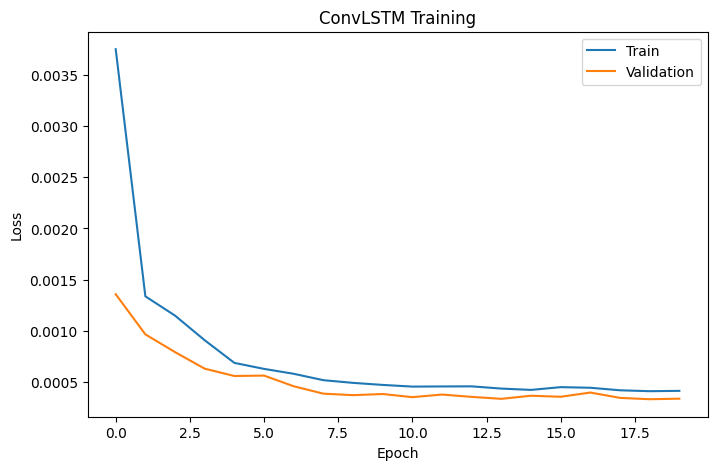

In [47]:
plt.figure(figsize=(8,5))

plt.plot(train_loss_history, label="Train")
plt.plot(val_loss_history, label="Validation")

plt.legend()

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("ConvLSTM Training")

plt.show()

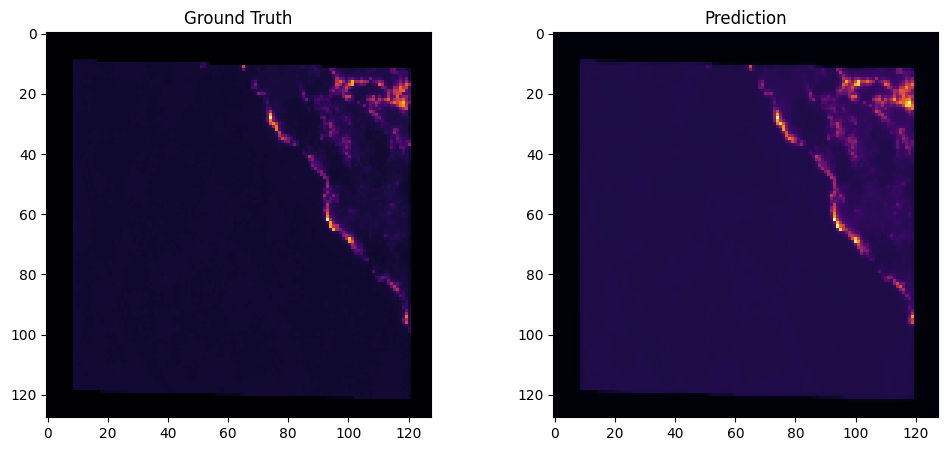

In [48]:
model.eval()

sample = x_val[0]

with torch.no_grad():

    pred = model(
        torch.tensor(sample)
        .unsqueeze(0)
        .unsqueeze(2)
        .float()
        .to(device)
    )

prediction = pred.squeeze().cpu().numpy()

ground_truth = y_val[0]

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(ground_truth, cmap="inferno")
plt.title("Ground Truth")

plt.subplot(1,2,2)
plt.imshow(prediction, cmap="inferno")
plt.title("Prediction")

plt.show()

In [ ]:
SEQ_LEN = 5
PREDICT_GAP = 5      # Predict 5 frames ahead

X = []
Y = []

for i in range(len(files) - SEQ_LEN - PREDICT_GAP):

    seq = []

    for j in range(SEQ_LEN):
        seq.append(read_tiff(files[i + j]))

    target = read_tiff(files[i + SEQ_LEN + PREDICT_GAP - 1])

    X.append(seq)
    Y.append(target)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print("Input:", X.shape)
print("Target:", Y.shape)

In [50]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

train_loader = DataLoader(
    FireDataset(x_train, y_train),
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    FireDataset(x_val, y_val),
    batch_size=8,
    shuffle=False
)

In [51]:
criterion = nn.L1Loss()

In [52]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [53]:
EPOCHS = 50

best_loss = float("inf")

train_history = []
val_history = []

for epoch in range(EPOCHS):

    model.train()
    train_loss = 0

    for x, y in train_loader:

        x = x.float().to(device)
        y = y.float().to(device)

        optimizer.zero_grad()

        pred = model(x)

        loss = criterion(pred, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()

    val_loss = 0

    with torch.no_grad():

        for x, y in val_loader:

            x = x.float().to(device)
            y = y.float().to(device)

            pred = model(x)

            loss = criterion(pred, y)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    scheduler.step(val_loss)

    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train {train_loss:.5f} | "
        f"Val {val_loss:.5f}"
    )

    if val_loss < best_loss:

        best_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_convlstm.pth"
        )

        print("Best model saved.")

Epoch 01 | Train 0.01783 | Val 0.01590
Best model saved.
Epoch 02 | Train 0.01648 | Val 0.01532
Best model saved.
Epoch 03 | Train 0.01595 | Val 0.01514
Best model saved.
Epoch 05 | Train 0.01582 | Val 0.01538
Epoch 06 | Train 0.01609 | Val 0.01519
Epoch 07 | Train 0.01603 | Val 0.01491
Best model saved.
Epoch 08 | Train 0.01620 | Val 0.01624
Epoch 09 | Train 0.01591 | Val 0.01521
Epoch 10 | Train 0.01555 | Val 0.01495
Epoch 11 | Train 0.01602 | Val 0.01516
Epoch 13 | Train 0.01540 | Val 0.01484
Best model saved.
Epoch 14 | Train 0.01550 | Val 0.01502
Epoch 15 | Train 0.01574 | Val 0.01513
Epoch 16 | Train 0.01549 | Val 0.01595
Epoch 17 | Train 0.01596 | Val 0.01510
Epoch 18 | Train 0.01548 | Val 0.01509
Epoch 19 | Train 0.01541 | Val 0.01490
Epoch 20 | Train 0.01543 | Val 0.01479
Best model saved.
Epoch 21 | Train 0.01554 | Val 0.01480
Epoch 22 | Train 0.01542 | Val 0.01491
Epoch 23 | Train 0.01566 | Val 0.01481
Epoch 24 | Train 0.01548 | Val 0.01502
Epoch 25 | Train 0.01533 | Val 0.0

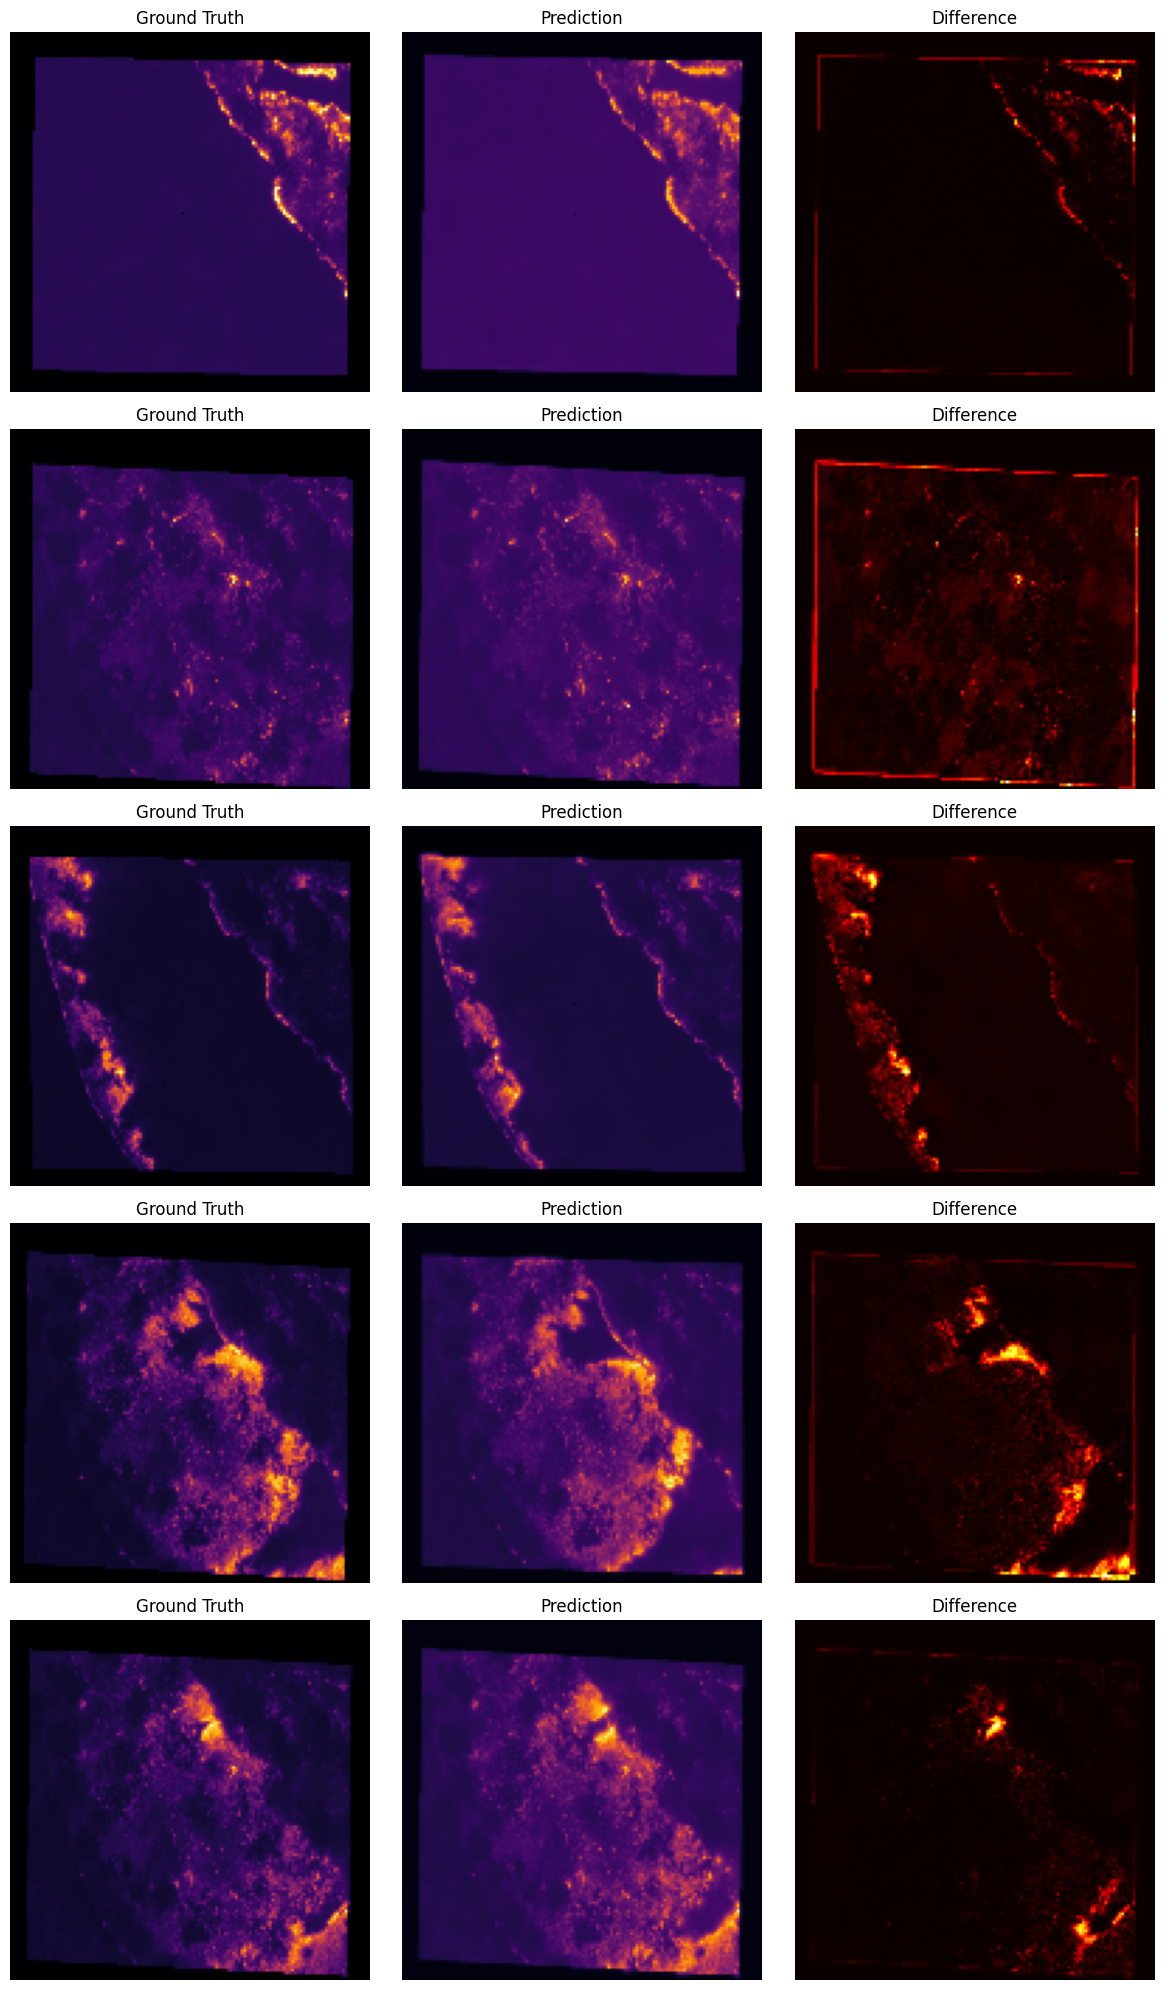

In [57]:
model.load_state_dict(torch.load("best_convlstm.pth"))
model.eval()

fig, ax = plt.subplots(5, 3, figsize=(12, 20))

for i in range(5):

    sample = torch.tensor(x_val[i]).unsqueeze(0).unsqueeze(2).float().to(device)

    with torch.no_grad():
        pred = model(sample)

    pred = pred.squeeze().cpu().numpy()

    gt = y_val[i]

    diff = np.abs(gt - pred)

    ax[i,0].imshow(gt, cmap="inferno")
    ax[i,0].set_title("Ground Truth")
    ax[i,0].axis("off")

    ax[i,1].imshow(pred, cmap="inferno")
    ax[i,1].set_title("Prediction")
    ax[i,1].axis("off")

    ax[i,2].imshow(diff, cmap="hot")
    ax[i,2].set_title("Difference")
    ax[i,2].axis("off")

plt.tight_layout()
plt.show()

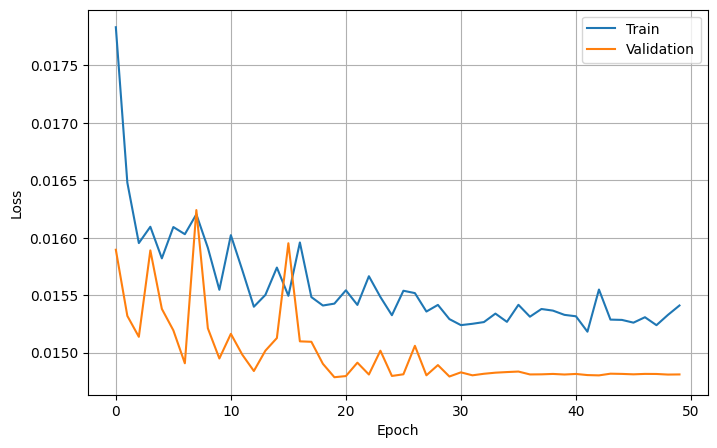

In [58]:
plt.figure(figsize=(8,5))

plt.plot(train_history, label="Train")
plt.plot(val_history, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.grid(True)

plt.show()

In [59]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

prediction = prediction.astype(np.float32)
ground_truth = ground_truth.astype(np.float32)

mse = mean_squared_error(
    ground_truth.flatten(),
    prediction.flatten()
)

mae = mean_absolute_error(
    ground_truth.flatten(),
    prediction.flatten()
)

rmse = np.sqrt(mse)

print("="*40)
print("Evaluation Metrics")
print("="*40)
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAE  : {mae:.6f}")

Evaluation Metrics
MSE  : 0.000240
RMSE : 0.015490
MAE  : 0.010348


In [60]:
from skimage.metrics import structural_similarity as ssim

score = ssim(
    ground_truth,
    prediction,
    data_range=1.0
)

print("SSIM :", score)

SSIM : 0.9412817712069863


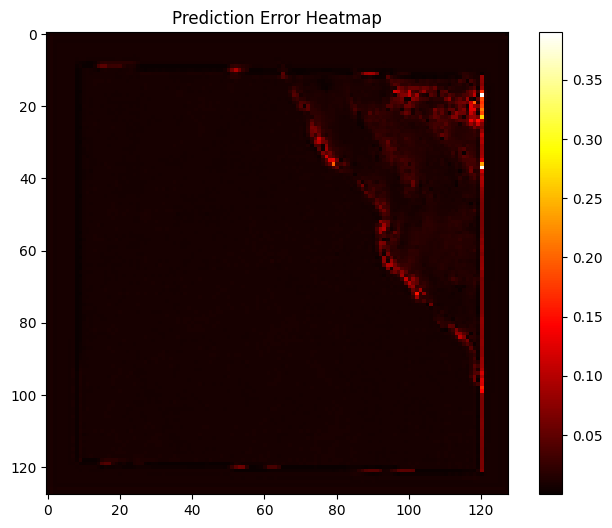

In [61]:
difference = np.abs(ground_truth - prediction)

plt.figure(figsize=(8,6))

plt.imshow(difference,cmap="hot")
plt.colorbar()

plt.title("Prediction Error Heatmap")

plt.show()

In [63]:
future_frames=[]

current=x_val[0].copy()

model.eval()

for step in range(10):

    inp=torch.tensor(current).unsqueeze(0).unsqueeze(2).float().to(device)

    with torch.no_grad():

        pred=model(inp)

    pred=pred.squeeze().cpu().numpy()

    future_frames.append(pred)

    current=np.concatenate(

        [
            current[1:],
            pred[np.newaxis]
        ],

        axis=0

    )

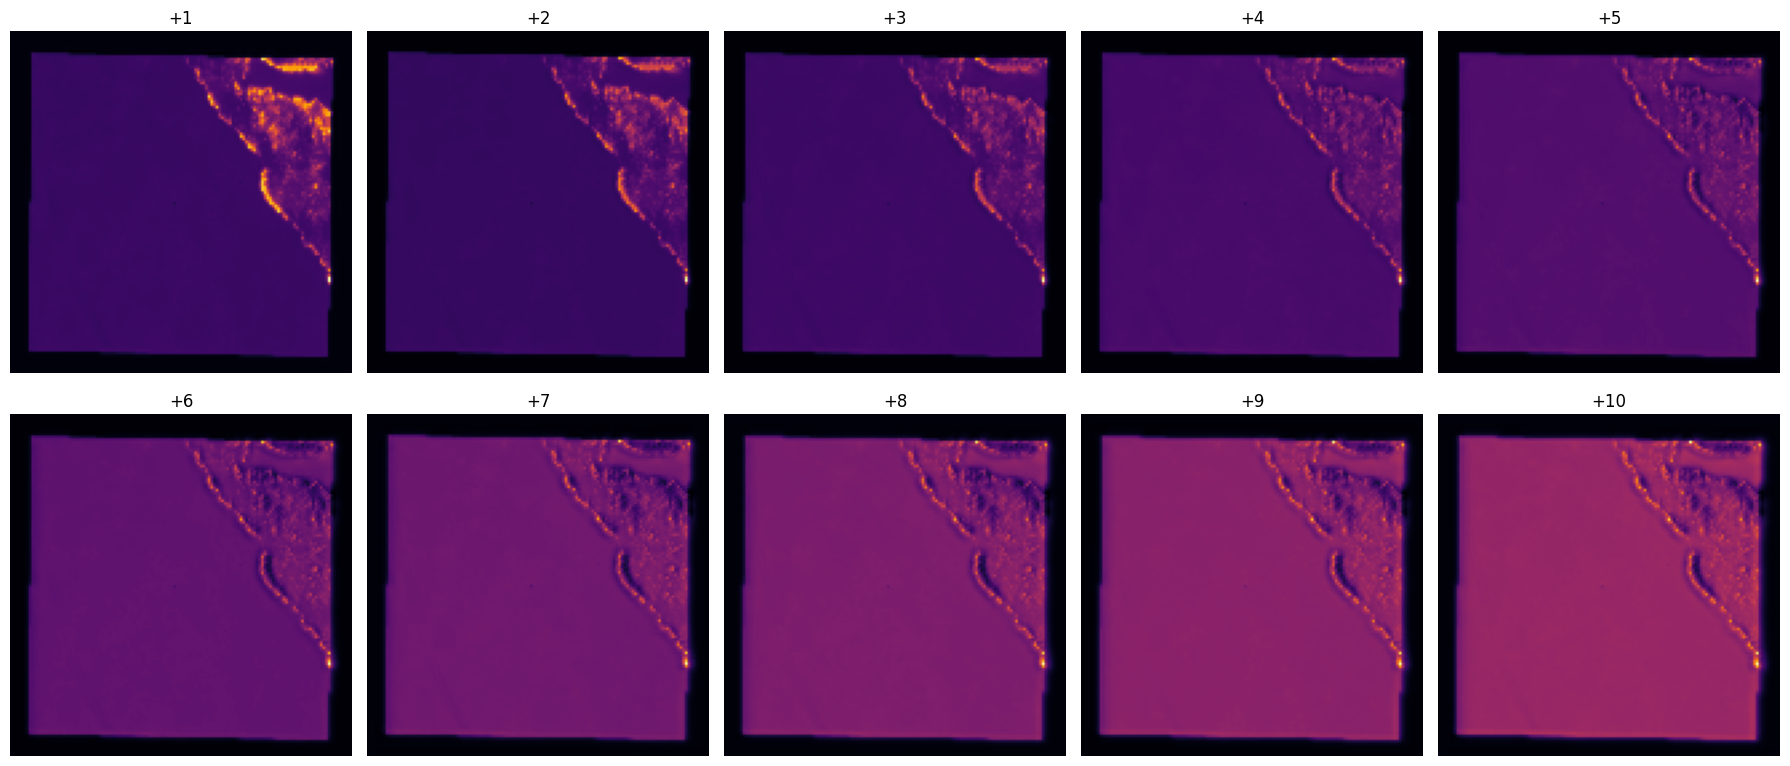

In [64]:
fig,ax=plt.subplots(2,5,figsize=(18,8))

for i in range(10):

    ax.flat[i].imshow(
        future_frames[i],
        cmap="inferno"
    )

    ax.flat[i].set_title(f"+{i+1}")

    ax.flat[i].axis("off")

plt.tight_layout()

plt.show()

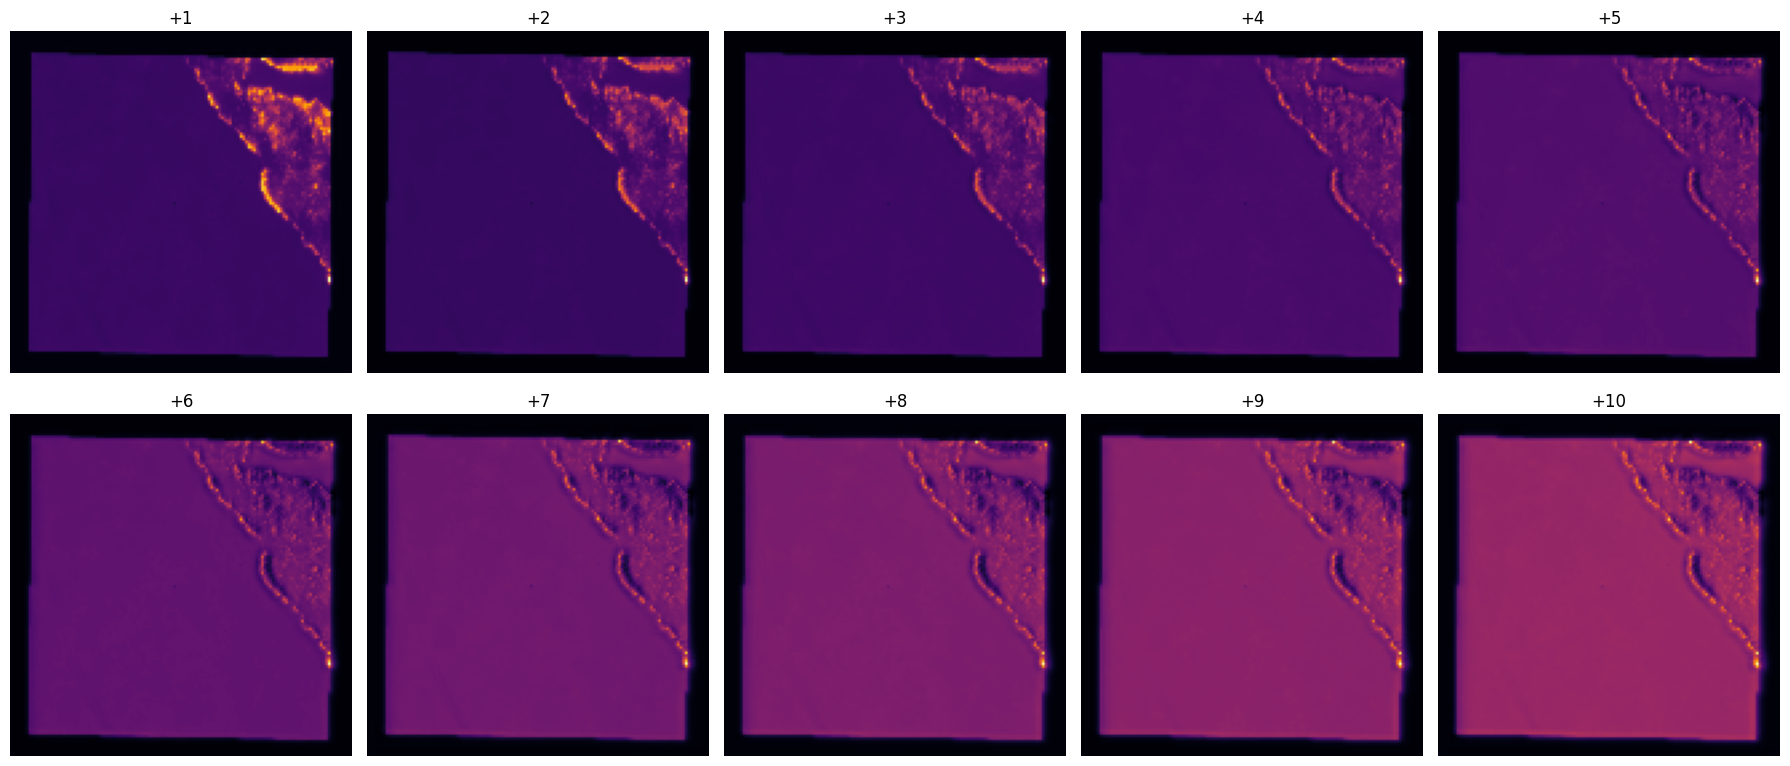

In [65]:
fig,ax=plt.subplots(2,5,figsize=(18,8))

for i in range(10):

    ax.flat[i].imshow(
        future_frames[i],
        cmap="inferno"
    )

    ax.flat[i].set_title(f"+{i+1}")

    ax.flat[i].axis("off")

plt.tight_layout()

plt.show()

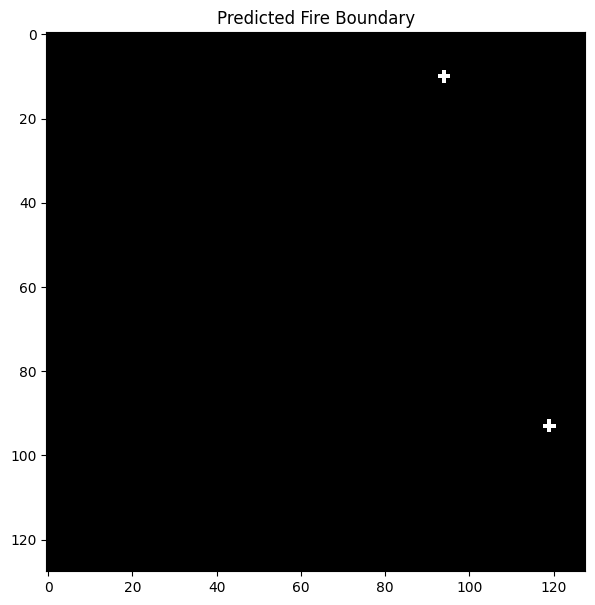

In [66]:
import cv2

pred=future_frames[-1]

binary=(pred>0.35).astype(np.uint8)

contours,_=cv2.findContours(

    binary,

    cv2.RETR_EXTERNAL,

    cv2.CHAIN_APPROX_SIMPLE

)

boundary=np.zeros_like(binary)

cv2.drawContours(

    boundary,

    contours,

    -1,

    1,

    2

)

plt.figure(figsize=(7,7))

plt.imshow(boundary,cmap="gray")

plt.title("Predicted Fire Boundary")

plt.show()

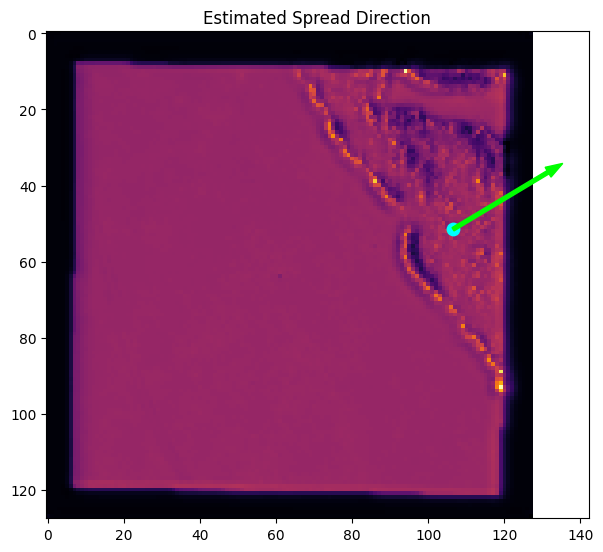

In [67]:
ys,xs=np.where(binary==1)

cx=np.mean(xs)

cy=np.mean(ys)

plt.figure(figsize=(7,7))

plt.imshow(pred,cmap="inferno")

plt.scatter(cx,cy,c="cyan",s=80)

plt.arrow(

    cx,

    cy,

    25,

    -15,

    color="lime",

    width=1

)

plt.title("Estimated Spread Direction")

plt.show()

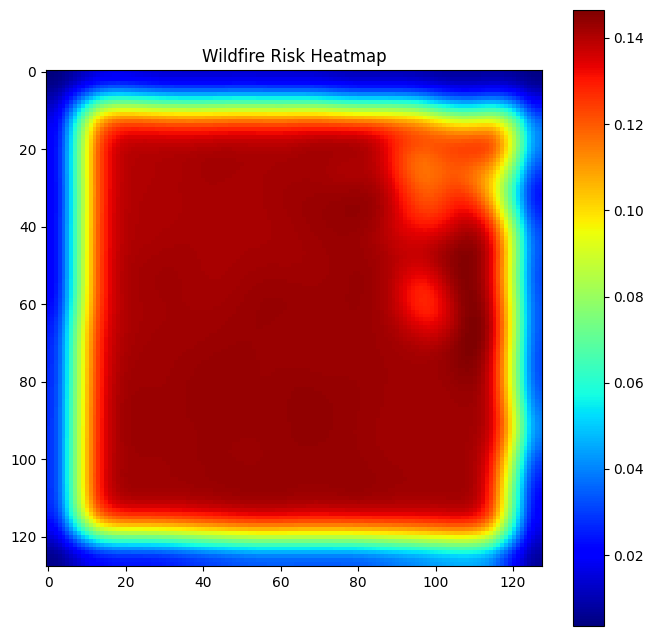

In [68]:
risk=cv2.GaussianBlur(

    pred,

    (31,31),

    0

)

plt.figure(figsize=(8,8))

plt.imshow(risk,cmap="jet")

plt.colorbar()

plt.title("Wildfire Risk Heatmap")

plt.show()

In [69]:
import os
import cv2
import numpy as np
import rasterio
from tqdm import tqdm

MASK_DIR = "/kaggle/working/fire_masks"
os.makedirs(MASK_DIR, exist_ok=True)

THRESHOLD = 0.55

for path in tqdm(files):

    with rasterio.open(path) as src:
        img = src.read(1)

    img = np.nan_to_num(img)

    img = cv2.resize(img, (128, 128))

    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    mask = (img > THRESHOLD).astype(np.uint8) * 255

    kernel = np.ones((3,3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    filename = os.path.basename(path).replace(".TIFF", ".png")

    cv2.imwrite(
        os.path.join(MASK_DIR, filename),
        mask
    )

print("Masks generated successfully.")

100%|██████████| 296/296 [00:04<00:00, 70.21it/s]

Masks generated successfully.


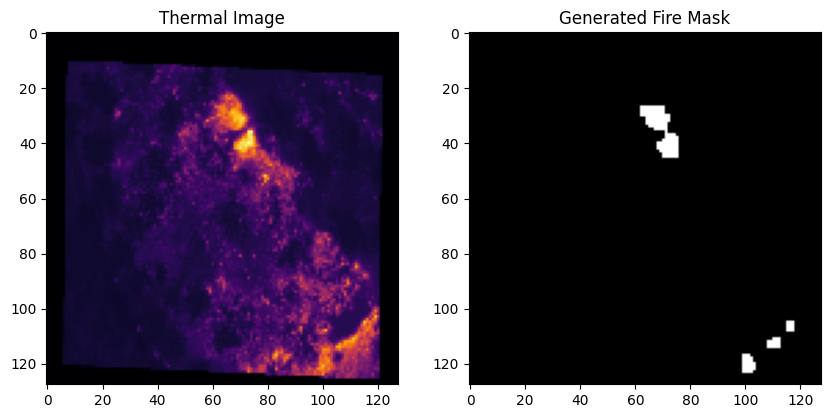

In [70]:
import random
import matplotlib.pyplot as plt

idx = random.randint(0, len(files)-1)

with rasterio.open(files[idx]) as src:
    img = src.read(1)

img = cv2.resize(img,(128,128))
img = (img-img.min())/(img.max()-img.min()+1e-8)

mask = cv2.imread(
    os.path.join(
        MASK_DIR,
        os.path.basename(files[idx]).replace(".TIFF",".png")
    ),
    0
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img,cmap="inferno")
plt.title("Thermal Image")

plt.subplot(1,2,2)
plt.imshow(mask,cmap="gray")
plt.title("Generated Fire Mask")

plt.show()

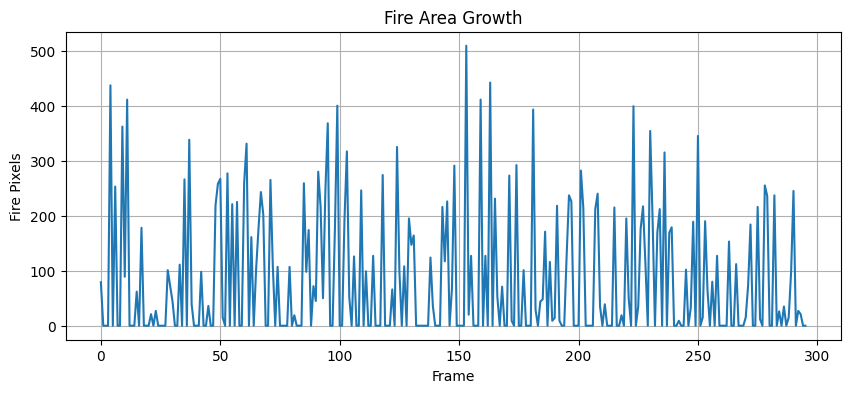

In [72]:
areas=[]

for f in os.listdir(MASK_DIR):

    mask=cv2.imread(
        os.path.join(MASK_DIR,f),
        0
    )

    area=np.sum(mask>0)

    areas.append(area)

plt.figure(figsize=(10,4))

plt.plot(areas)

plt.xlabel("Frame")

plt.ylabel("Fire Pixels")

plt.title("Fire Area Growth")

plt.grid()

plt.show()

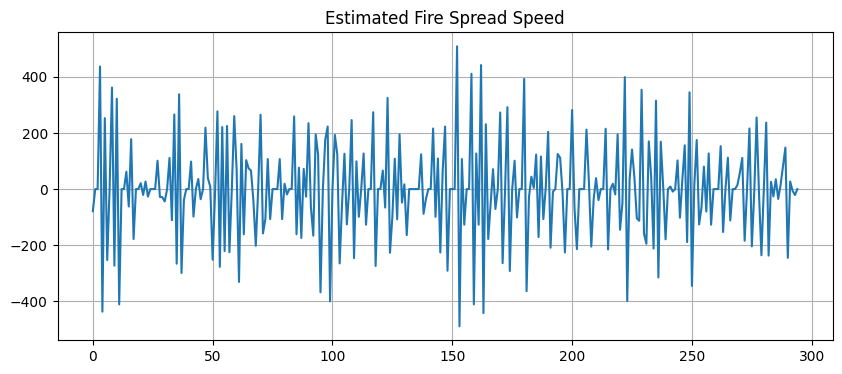

In [76]:
speed=[]

for i in range(1,len(areas)):

    speed.append(
        areas[i]-areas[i-1]
    )

plt.figure(figsize=(10,4))

plt.plot(speed)

plt.title("Estimated Fire Spread Speed")

plt.grid()

plt.show()

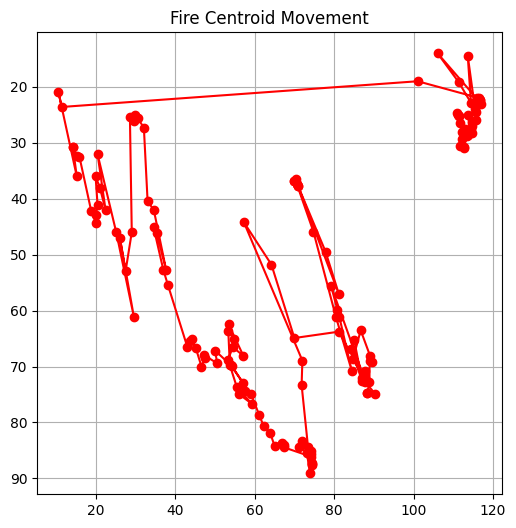

In [77]:
centers=[]

for f in sorted(os.listdir(MASK_DIR)):

    mask=cv2.imread(
        os.path.join(MASK_DIR,f),
        0
    )

    ys,xs=np.where(mask>0)

    if len(xs)==0:
        continue

    centers.append((np.mean(xs),np.mean(ys)))

xs=[c[0] for c in centers]
ys=[c[1] for c in centers]

plt.figure(figsize=(6,6))

plt.plot(xs,ys,"r-o")

plt.gca().invert_yaxis()

plt.title("Fire Centroid Movement")

plt.grid()

plt.show()

In [78]:
model.eval()

future_predictions = []

sequence = x_val[0].copy()

for step in range(10):

    inp = torch.tensor(sequence)\
        .unsqueeze(0)\
        .unsqueeze(2)\
        .float()\
        .to(device)

    with torch.no_grad():
        pred = model(inp)

    pred = pred.squeeze().cpu().numpy()

    future_predictions.append(pred)

    sequence = np.concatenate(
        [sequence[1:], pred[np.newaxis]],
        axis=0
    )

print("Generated", len(future_predictions), "future frames")

Generated 10 future frames


In [90]:
future_masks = []

THRESHOLD = 0.45

for pred in future_predictions:

    mask = (pred > THRESHOLD).astype(np.uint8)

    kernel = np.ones((3,3), np.uint8)

    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    future_masks.append(mask)

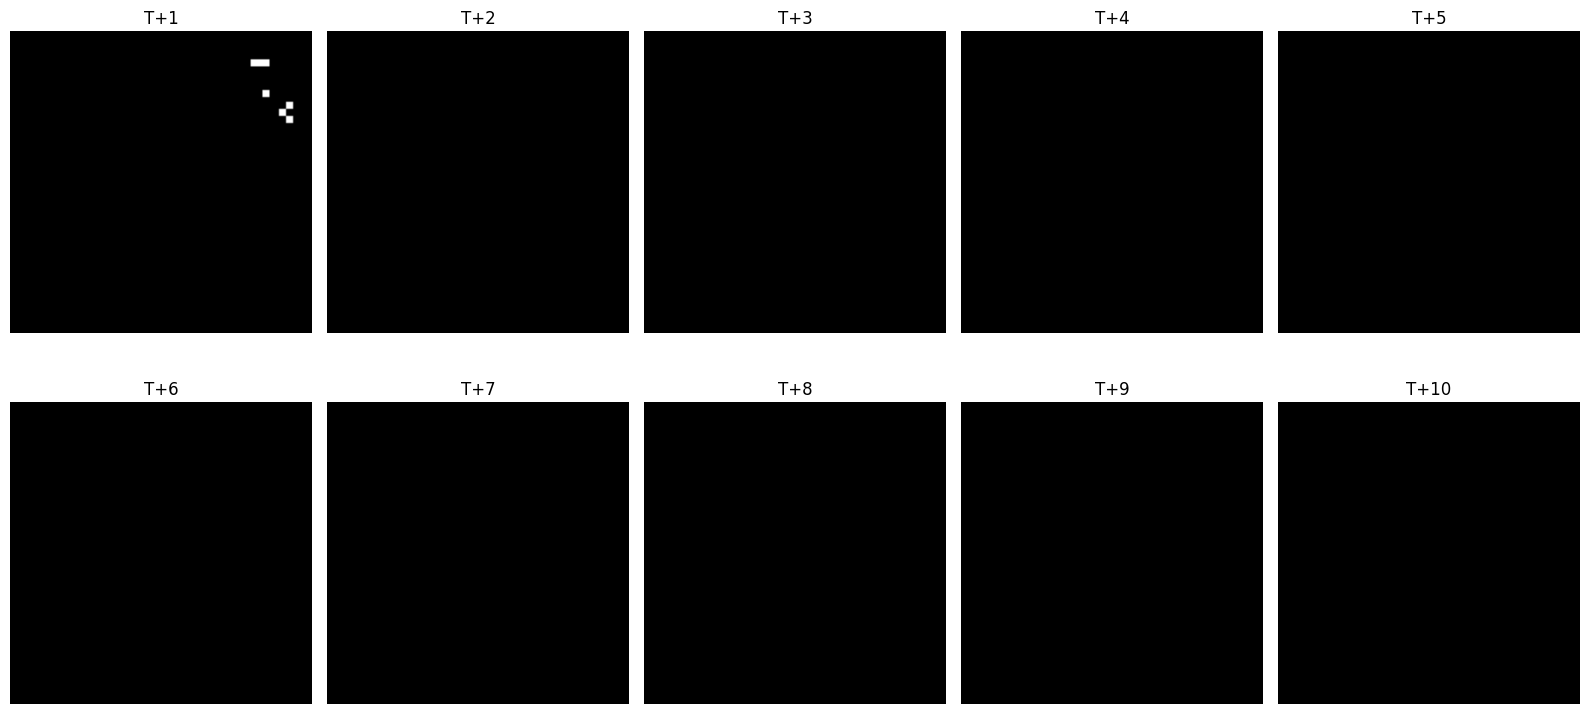

In [94]:
fig, ax = plt.subplots(2,5, figsize=(16,8))

for i in range(10):

    ax.flat[i].imshow(
        future_masks[i],
        cmap="gray"
    )

    ax.flat[i].set_title(f"T+{i+1}")

    ax.flat[i].axis("off")

plt.tight_layout()

plt.show()